# UTS Machine Learning – Tugas 3: Clustering Segmentasi Pelanggan

Notebook ini **mandiri**: semua fungsi ada di dalamnya, tidak mengimpor berkas lain. Bisa dijalankan di Google Colab atau lokal.

**Cara memakai**
1. Letakkan `clustering.csv.gz` di folder yang sama dengan notebook (di Colab, sel pertama akan meminta unggah berkas).
2. Jalankan semua sel (*Runtime → Run all*). Waktu total sekitar 25–30 menit pada 2 inti CPU; sel terberat adalah prediktabilitas fitur, BIC GMM, dan perbandingan metode.
3. Hasil: `cluster.csv` (kolom `id_pelanggan,cluster`) dan tabel pendukung di folder `output/`.

**Alur**: audit data → anomali → preprocessing → seleksi fitur → jumlah cluster dan perbandingan metode → stabilitas → label akhir → profil segmen dan aksi pemasaran.

Seed global 42. Hasil angka bisa sedikit berbeda bila versi scikit-learn berbeda dari yang tercetak di sel pertama; nomor cluster juga bisa tertukar (lihat catatan di bagian profil).

In [1]:
import os, sys, json, time, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import sklearn, scipy
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestCentroid
from sklearn.ensemble import IsolationForest, HistGradientBoostingRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import (silhouette_score, calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score as ari)
warnings.filterwarnings('ignore')

SEED = 42
K = 6                                                    # jumlah cluster final (alasan di bagian 6)
DATA_PATH = os.environ.get('CLUSTERING_CSV', 'clustering.csv.gz')
OUT = 'output/'; os.makedirs(OUT, exist_ok=True)

if not os.path.exists(DATA_PATH):
    try:                                                 # Google Colab: unggah berkas langsung
        from google.colab import files
        print('Unggah clustering.csv.gz ...'); DATA_PATH = list(files.upload())[0]
    except ImportError:
        raise FileNotFoundError('clustering.csv.gz tidak ditemukan di folder kerja.')

pd.set_option('display.width', 220, 'display.max_columns', 80, 'display.max_rows', 120)
# warna: palet kategorikal tervalidasi (biru, oranye, aqua), teks tidak memakai warna seri
BLUE, ORANGE, AQUA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#e34948'
INK, INK2, MUTED, GRID, SURF = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': INK2,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK, 'axes.grid': True, 'grid.color': GRID,
                     'grid.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlesize': 11,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 10, 'figure.dpi': 110,
                     'legend.frameon': False})
print('berkas data :', os.path.basename(DATA_PATH))
print('python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| scipy', scipy.__version__, '| seed', SEED)

berkas data : clustering.csv.gz
python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scipy 1.18.1 | seed 42


## 0. Fungsi preprocessing

Semua transformasi ada di sel ini dan dipakai ulang oleh sel-sel berikutnya.

- **Variabel miring** (recency, frekuensi, keranjang, retur, ulasan, sesi, lama member): $\log$ atau $\log(1+x)$.
- **Persentase pesanan** di $(0,1)$: $\operatorname{logit}(p)=\ln\frac{p}{1-p}$, dengan $p$ dibatasi ke $[10^{-3},\,1-10^{-3}]$.
- **Data komposisional** (porsi kategori dan porsi jam, masing-masing berjumlah 1): transformasi *centered log-ratio*

$$\operatorname{clr}(x)_j=\ln x_j-\frac{1}{D}\sum_{k=1}^{D}\ln x_k .$$

  Nilai nol diganti $\delta=5\times10^{-5}$ (setengah resolusi data, yang dibulatkan ke 4 desimal), lalu dinormalisasi ulang.
- `belanja_90h` $=$ `frekuensi_90h` $\times$ `rata2_keranjang` (identitas, terbukti di bagian 1), jadi `belanja_90h` redundan dan tidak dipakai.
- Delapan kategori yang terbukti noise (bagian 4) digabung menjadi satu bagian "sisa" sebelum CLR (amalgamasi), sehingga CLR tetap valid.

In [2]:
"""Preprocessing untuk Tugas 3 (clustering). Semua transformasi di sini, dipakai ulang oleh skrip lain."""
import numpy as np
import pandas as pd

SEED = 42
KATEGORI = ['porsi_fashion','porsi_elektronik','porsi_kecantikan','porsi_rumah_tangga','porsi_makanan_minuman',
            'porsi_ibu_bayi','porsi_olahraga','porsi_hobi','porsi_otomotif','porsi_kesehatan','porsi_buku_alat_tulis',
            'porsi_voucher_digital','porsi_gadget_aksesoris','porsi_perabot','porsi_pertanian','porsi_lainnya']
JAM = ['porsi_jam_pagi','porsi_jam_siang','porsi_jam_sore','porsi_jam_malam']
PERSEN = ['persen_voucher','persen_flash_sale','persen_paylater','persen_cod']
NOISE = [f'n{i:02d}' for i in range(1, 16)]
AKTIVITAS_APP = ['sesi_per_minggu','durasi_sesi_menit','klik_iklan_30h','wishlist']


def load(path):
    return pd.read_csv(path)


def deteksi_bot(df):
    """Aturan anomali: lonjakan serentak di tiga fitur aktivitas aplikasi (lihat audit.py untuk buktinya)."""
    return ((df.sesi_per_minggu > 60) & (df.klik_iklan_30h > 60) & (df.wishlist > 60)).to_numpy()


def clr(P, delta=None):
    """Centered log-ratio. Nol diganti delta (resolusi data 1e-4 -> delta = 5e-5), lalu renormalisasi."""
    P = np.asarray(P, float)
    if delta is None:
        delta = 5e-5
    P = np.where(P <= 0, delta, P)
    P = P / P.sum(1, keepdims=True)
    L = np.log(P)
    return L - L.mean(1, keepdims=True)


def logit(p, eps=1e-3):
    p = np.clip(np.asarray(p, float), eps, 1 - eps)
    return np.log(p / (1 - p))


def build_features(df, delta=5e-5):
    """Kembalikan (DataFrame fitur mentah-transformasi, dict grup -> daftar kolom). Belum distandarisasi."""
    F = pd.DataFrame(index=df.index)
    aktif = (df.frekuensi_90h > 0).astype(float)
    # --- RFM / nilai belanja (skew -> log) ---
    F['log_recency'] = np.log1p(df.recency_hari)
    F['log_frek90'] = np.log1p(df.frekuensi_90h)
    F['log_belanja90'] = np.log1p(df.belanja_90h)
    F['log_keranjang'] = np.log(df.rata2_keranjang).fillna(0.0)   # NaN struktural: frekuensi_90h == 0
    F['log_item'] = np.log(df.item_per_pesanan)
    F['log_belanja30'] = np.log1p(df.belanja_30h)
    F['log_frek30'] = np.log1p(df.frekuensi_30h)
    F['aktif90'] = aktif
    # --- komposisi -> CLR ---
    C = clr(df[KATEGORI].to_numpy(), delta)
    for j, c in enumerate(KATEGORI):
        F['clr_' + c] = C[:, j]
    T = clr(df[JAM].to_numpy(), delta)
    for j, c in enumerate(JAM):
        F['clr_' + c] = T[:, j]
    # --- proporsi pesanan (0,1) -> logit ---
    for c in PERSEN:
        F['logit_' + c] = logit(df[c])
    # --- perilaku / profil ---
    F['log_retur'] = np.log1p(df.retur_90h)
    F['rating'] = df.rating_beri_rata2
    F['log_ulasan'] = np.log1p(df.ulasan_90h)
    F['log_sesi'] = np.log(df.sesi_per_minggu)
    F['log_durasi'] = np.log(df.durasi_sesi_menit)
    F['log_konversi'] = np.log1p(df.rasio_konversi)
    F['log_member'] = np.log(df.lama_member_bulan)
    F['umur'] = df.umur
    F['kota_tier'] = df.kota_tier
    F['perangkat_ios'] = (df.perangkat == 'ios').astype(float)
    F['perangkat_web'] = (df.perangkat == 'web').astype(float)
    F['log_alamat'] = np.log(df.jumlah_alamat)
    F['log_wishlist'] = np.log1p(df.wishlist)
    F['log_klik'] = np.log1p(df.klik_iklan_30h)
    # --- noise kandidat (transformasi seperlunya agar tidak didominasi ekor) ---
    for c in NOISE:
        x = df[c].to_numpy(float)
        F['z_' + c] = np.sign(x) * np.log1p(np.abs(x)) if np.abs(x).max() > 300 else x
    groups = {
        'rfm': [c for c in F if c.startswith('log_') and c in
                ['log_recency','log_frek90','log_belanja90','log_keranjang','log_item','log_belanja30','log_frek30']] + ['aktif90'],
        'kategori': ['clr_' + c for c in KATEGORI],
        'jam': ['clr_' + c for c in JAM],
        'persen': ['logit_' + c for c in PERSEN],
        'perilaku': ['log_retur','rating','log_ulasan','log_konversi'],
        'app': ['log_sesi','log_durasi','log_wishlist','log_klik'],
        'profil': ['log_member','umur','kota_tier','perangkat_ios','perangkat_web','log_alamat'],
        'noise_kandidat': ['z_' + c for c in NOISE],
    }
    return F, groups


# ---------------------------------------------------------------------------------------------
# Matriks model final (hasil seleksi fitur; bukti: tabel_prediktabilitas_fitur.csv dan select_features.py)
# ---------------------------------------------------------------------------------------------
KAT_INFORMATIF = ['porsi_fashion','porsi_elektronik','porsi_kecantikan','porsi_rumah_tangga','porsi_makanan_minuman',
                  'porsi_ibu_bayi','porsi_voucher_digital','porsi_gadget_aksesoris']
KAT_NOISE = [c for c in KATEGORI if c not in KAT_INFORMATIF]
FITUR_FINAL = (['log_recency', 'log_frek90', 'log_keranjang', 'log_item', 'log_retur', 'log_ulasan', 'log_sesi']
               + ['logit_' + c for c in PERSEN]
               + ['clr_' + c for c in JAM]
               + ['clr_kat_' + c for c in KAT_INFORMATIF] + ['clr_kat_sisa']
               + ['log_member', 'umur', 'perangkat_ios', 'perangkat_web'])
# kolom yang tidak terdefinisi untuk pelanggan tanpa transaksi (frekuensi_90h == 0)
KOLOM_STRUKTURAL = ['log_keranjang', 'log_ulasan']


def build_model_matrix(df, delta=5e-5):
    """Matriks fitur final (belum distandarisasi). Kolom struktural diisi NaN untuk pelanggan tanpa transaksi."""
    F, _ = build_features(df, delta)
    M = pd.DataFrame(index=df.index)
    for c in ['log_recency', 'log_frek90', 'log_keranjang', 'log_item', 'log_retur', 'log_ulasan', 'log_sesi',
              'log_member', 'umur', 'perangkat_ios', 'perangkat_web'] + ['logit_' + c for c in PERSEN] + ['clr_' + c for c in JAM]:
        M[c] = F[c]
    parts = df[KAT_INFORMATIF].copy()
    parts['sisa'] = df[KAT_NOISE].sum(axis=1)          # amalgamasi: kategori noise digabung jadi satu bagian
    C = clr(parts.to_numpy(), delta)
    for j, c in enumerate(KAT_INFORMATIF + ['sisa']):
        M['clr_kat_' + c] = C[:, j]
    M = M[FITUR_FINAL]
    nol = (df.frekuensi_90h == 0).to_numpy()
    for c in KOLOM_STRUKTURAL:
        M.loc[nol, c] = np.nan
    return M, nol

## 1. Audit data

Pemeriksaan dimensi, nilai hilang, identitas antar-kolom, dan konsistensi. Hasil disimpan ke `output/tabel_audit.json`.

In [3]:
df = load(DATA_PATH); bot = deteksi_bot(df); nol_all = (df.frekuensi_90h == 0)
a = {}
a['n_baris'], a['n_kolom'] = df.shape
a['id_duplikat'] = int(df.id_pelanggan.duplicated().sum())
a['missing'] = {c: float(v) for c, v in df.isna().mean().items() if v > 0}
a['missing_rata2_keranjang_sama_dengan_frek0'] = bool((df.rata2_keranjang.isna() == nol_all).all())
a['frek0_n'] = int(nol_all.sum())
a['jumlah_kolom_n_di_data_vs_kamus'] = [len([c for c in df if c.startswith('n') and c[1:].isdigit()]), 10]
a['sum_porsi_kategori_min_max'] = [float(df[KATEGORI].sum(axis=1).min()), float(df[KATEGORI].sum(axis=1).max())]
a['sum_porsi_jam_min_max'] = [float(df[JAM].sum(axis=1).min()), float(df[JAM].sum(axis=1).max())]
a['belanja30_lebih_besar_belanja90'] = int((df.belanja_30h > df.belanja_90h + 1).sum())
a['frek30_lebih_besar_frek90'] = int((df.frekuensi_30h > df.frekuensi_90h).sum())
a['rasio_konversi_di_atas_1'] = int((df.rasio_konversi > 1).sum())
a['recency_di_atas_90'] = int((df.recency_hari > 90).sum())
a['belanja_per_frek_dibagi_keranjang_min_max'] = [float(x) for x in ((df.belanja_90h / df.frekuensi_90h.replace(0, np.nan)) / df.rata2_keranjang).agg(['min', 'max'])]
a['frek_hitung'] = {int(k): int(v) for k, v in df.frekuensi_90h.value_counts().sort_index().head(5).items()}
nc = [c for c in df if c.startswith('n') and c[1:].isdigit()]; oth = [c for c in df.select_dtypes('number') if c not in nc]
R = df[oth].rank()
a['maks_abs_spearman_n_vs_fitur_lain'] = float(max(R.corrwith(df[c].rank()).abs().max() for c in nc))
json.dump(a, open(OUT + 'tabel_audit.json', 'w'), indent=1, default=float)
print(json.dumps(a, indent=1, default=float))

{
 "n_baris": 120000,
 "n_kolom": 60,
 "id_duplikat": 0,
 "missing": {
  "rata2_keranjang": 0.056133333333333334
 },
 "missing_rata2_keranjang_sama_dengan_frek0": true,
 "frek0_n": 6736,
 "jumlah_kolom_n_di_data_vs_kamus": [
  15,
  10
 ],
 "sum_porsi_kategori_min_max": [
  0.9995999999999997,
  1.0005
 ],
 "sum_porsi_jam_min_max": [
  0.9998999999999998,
  1.0001000000000002
 ],
 "belanja30_lebih_besar_belanja90": 101,
 "frek30_lebih_besar_frek90": 0,
 "rasio_konversi_di_atas_1": 656,
 "recency_di_atas_90": 6655,
 "belanja_per_frek_dibagi_keranjang_min_max": [
  0.9972413793103448,
  1.0035714285714286
 ],
 "frek_hitung": {
  "0": 6736,
  "1": 9650,
  "2": 9684,
  "3": 8908,
  "4": 8589
 },
 "maks_abs_spearman_n_vs_fitur_lain": 0.010158479108074926
}


**Temuan audit**

- Satu-satunya nilai hilang ada di `rata2_keranjang` (5,6%), dan hilangnya **tepat sama** dengan `frekuensi_90h = 0`: hilang secara struktural, bukan acak.
- Rasio $\text{belanja\_90h}/\text{frekuensi\_90h}/\text{rata2\_keranjang}$ berada di 0,997–1,004, jadi `belanja_90h` redundan.
- Komposisi berjumlah 1 (selisih ≤ 0,0005 akibat pembulatan).
- Pelanggaran konsistensi: `belanja_30h > belanja_90h` (101 baris), `rasio_konversi > 1` (656 baris, secara definisi tidak mungkin), dan kamus menyebut `n01–n10` padahal berkas memuat `n01–n15`.
- Jumlah pelanggan per frekuensi 0, 1, 2, 3 adalah 6.736, 9.650, 9.684, 8.908: frekuensi 0 **bukan lonjakan terpisah**, melainkan ujung bawah distribusi yang mulus. Pelanggan tanpa transaksi bukan segmen sendiri.

## 2. Anomali: kelompok bot di fitur aktivitas aplikasi

`sesi_per_minggu`, `klik_iklan_30h`, dan `wishlist` melonjak **serentak** pada sekelompok pelanggan. Histogram di bawah memakai sumbu y logaritmik karena kelompok ini kecil.

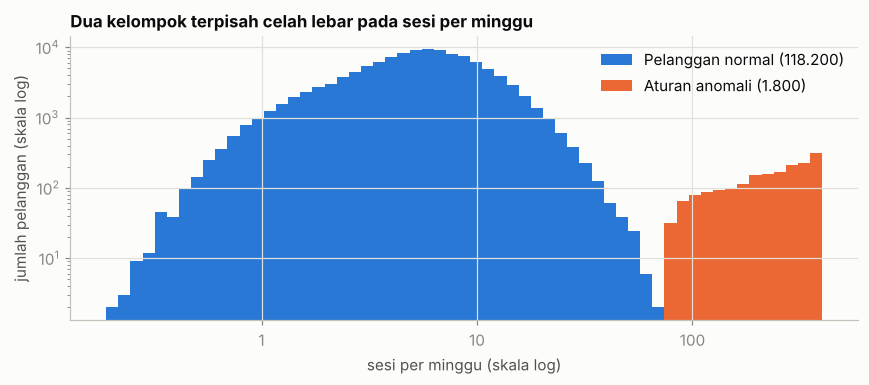

Median fitur aplikasi:


,anomali (aturan),normal
sesi_per_minggu,241.11,5.44
durasi_sesi_menit,0.60,8.01
klik_iklan_30h,200.00,5.00
wishlist,150.00,9.00


Aturan: sesi_per_minggu > 60 & klik_iklan_30h > 60 & wishlist > 60  -> 1800 pelanggan (1.5%)
Persentil sesi_per_minggu 95/97/98/99/99,5: [ 17.2  22.   28.5 187.1 294.7]


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.log10(df.sesi_per_minggu); bins = np.linspace(x.min(), x.max(), 60)
ax.hist(x[~bot], bins=bins, color=BLUE, label=f'Pelanggan normal ({(~bot).sum():,})'.replace(',', '.'))
ax.hist(x[bot], bins=bins, color=ORANGE, label=f'Aturan anomali ({bot.sum():,})'.replace(',', '.'))
ax.set_yscale('log'); ax.set_xticks([0, 1, 2]); ax.set_xticklabels(['1', '10', '100'])
ax.set_xlabel('sesi per minggu (skala log)'); ax.set_ylabel('jumlah pelanggan (skala log)')
ax.set_title('Dua kelompok terpisah celah lebar pada sesi per minggu'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

app = ['sesi_per_minggu', 'durasi_sesi_menit', 'klik_iklan_30h', 'wishlist']
tabel = pd.concat({'anomali (aturan)': df.loc[bot, app].median(), 'normal': df.loc[~bot, app].median()}, axis=1).round(2)
print('Median fitur aplikasi:'); display(tabel)
print('Aturan: sesi_per_minggu > 60 & klik_iklan_30h > 60 & wishlist > 60  ->', int(bot.sum()), 'pelanggan', f'({bot.mean():.1%})')
print('Persentil sesi_per_minggu 95/97/98/99/99,5:', np.percentile(df.sesi_per_minggu, [95, 97, 98, 99, 99.5]).round(1))

**Validasi independen**: Isolation Forest pada empat fitur aplikasi, dengan proporsi kontaminasi yang sama, harus menandai himpunan yang sama bila aturan di atas memang menemukan satu kelompok yang berbeda (hasilnya di bagian 7). Fitur belanja kelompok ini tampak normal, jadi anomalinya hanya pada perilaku aplikasi (pola bot atau scraper). Hanya kelompok ini yang diberi label `-1`: label `-1` yang salah merusak ARI, karena anomali referensi dikeluarkan dari perhitungan ARI tetapi pelanggan biasa tidak.

## 3. Matriks fitur

Di sini `build_model_matrix` menghasilkan fitur final. Pelanggan tanpa transaksi (`frekuensi_90h = 0`) diberi `NaN` pada kolom yang nol atau tidak terdefinisi secara struktural (`log_keranjang`, `log_ulasan`).

> **Catatan penting.** Percobaan awal yang mengisi nol pada kolom itu menghasilkan "cluster" berukuran tepat 6.647 (semua pelanggan tanpa transaksi non-bot) pada setiap seed. Itu artefak massa titik pada fitur yang nol secara struktural, bukan segmen. Karena itu model dilatih hanya pada pelanggan **dengan transaksi**, dan pelanggan tanpa transaksi diberi segmen belakangan memakai dimensi yang teramati saja (bagian 8).

Pada `cols`, fitur `perangkat_*` dikeluarkan: ia berupa biner dan menggeser partisi besar-besaran bila dimasukkan (ablasi di bagian 5). `perangkat` dipakai sebagai **validasi** di bagian profil.

In [5]:
M, nol = build_model_matrix(df)
cols = [c for c in M.columns if not c.startswith('perangkat')]
akt = (~bot) & (~nol)                                   # pelanggan non-bot dengan transaksi: data pelatihan
Fall, G = build_features(df)
rng = np.random.default_rng(SEED)                       # dipakai di bagian 7 (urutan penarikan sampel tetap)
print('anomali (bot):', int(bot.sum()), '| tanpa transaksi (non-bot):', int((nol & ~bot).sum()), '| aktif (pelatihan):', int(akt.sum()))
print(len(cols), 'fitur terpilih:'); print(cols)
sc = StandardScaler().fit(M.loc[akt, cols]); X = sc.transform(M.loc[akt, cols])
def km(X, k=K, n_init=10, seed=SEED): return KMeans(k, n_init=n_init, random_state=seed).fit(X)
def sil(X, l, n=10000):
    i = np.random.default_rng(0).choice(len(X), n, replace=False); return silhouette_score(X[i], l[i])

anomali (bot): 1800 | tanpa transaksi (non-bot): 6647 | aktif (pelatihan): 111553
26 fitur terpilih:
['log_recency', 'log_frek90', 'log_keranjang', 'log_item', 'log_retur', 'log_ulasan', 'log_sesi', 'logit_persen_voucher', 'logit_persen_flash_sale', 'logit_persen_paylater', 'logit_persen_cod', 'clr_porsi_jam_pagi', 'clr_porsi_jam_siang', 'clr_porsi_jam_sore', 'clr_porsi_jam_malam', 'clr_kat_porsi_fashion', 'clr_kat_porsi_elektronik', 'clr_kat_porsi_kecantikan', 'clr_kat_porsi_rumah_tangga', 'clr_kat_porsi_makanan_minuman', 'clr_kat_porsi_ibu_bayi', 'clr_kat_porsi_voucher_digital', 'clr_kat_porsi_gadget_aksesoris', 'clr_kat_sisa', 'log_member', 'umur']


## 4. Seleksi fitur, bukti 1: prediktabilitas

Segmen laten membuat fitur-fiturnya **saling bergantung**. Maka setiap fitur diprediksi dari semua fitur lain dengan gradient boosting ($R^2$ validasi silang 3-lipat, 30.000 baris):

- $R^2\approx 0$: fitur independen dari semua yang lain, sehingga tidak membawa struktur segmen (noise).
- $R^2\approx 1$: fitur adalah identitas atau turunan dari fitur lain, sehingga redundan dan akan terhitung dua kali.

Untuk kategori CLR, kategori lain dikeluarkan dari prediktor karena penutupan komposisi memberi ketergantungan semu. *(Sel ini memakan beberapa menit.)*

In [6]:
dp = df[(~bot) & (df.frekuensi_90h > 0)].reset_index(drop=True)
Fp, Gp = build_features(dp)
Fp['share_frek30'] = dp.frekuensi_30h / dp.frekuensi_90h
Fp['share_belanja30'] = (dp.belanja_30h / dp.belanja_90h).clip(upper=1.5)
cols_p = [c for c in Fp if c != 'aktif90' and c not in ('log_belanja30', 'log_frek30')]
rng_p = np.random.default_rng(SEED); idx_p = rng_p.choice(len(Fp), 30000, replace=False)
Sp = Fp.iloc[idx_p][cols_p].reset_index(drop=True)
r2 = {}
for c in cols_p:
    others = [x for x in cols_p if x != c and x not in ('log_belanja90',)] if c != 'log_belanja90' else [x for x in cols_p if x != c]
    if c.startswith('clr_porsi_') and not c.startswith('clr_porsi_jam'):   # kategori CLR: jangan pakai kategori lain
        others = [x for x in others if not (x.startswith('clr_porsi_') and not x.startswith('clr_porsi_jam'))]
    if c.startswith('clr_porsi_jam'):
        others = [x for x in others if not x.startswith('clr_porsi_jam')]
    mdl = HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=SEED)
    r2[c] = cross_val_score(mdl, Sp[others], Sp[c], cv=3, scoring='r2').mean()
pred = pd.Series(r2).sort_values(ascending=False).round(4).rename('r2_cv')
pred.to_csv(OUT + 'tabel_prediktabilitas_fitur.csv')
print('Fitur dengan R2 >= 0,9 (redundan):', list(pred[pred >= 0.9].index))
print('Fitur dengan R2 < 0,015 (independen / noise):'); print(pred[pred < 0.015].to_string())

Fitur dengan R2 >= 0,9 (redundan): ['log_belanja90', 'log_frek90', 'log_sesi', 'log_konversi']
Fitur dengan R2 < 0,015 (independen / noise):
clr_porsi_perabot            0.0133
clr_porsi_pertanian          0.0099
clr_porsi_buku_alat_tulis   -0.0003
z_n14                       -0.0008
clr_porsi_hobi              -0.0014
clr_porsi_lainnya           -0.0014
z_n09                       -0.0015
clr_porsi_otomotif          -0.0015
clr_porsi_olahraga          -0.0016
clr_porsi_kesehatan         -0.0016
z_n01                       -0.0017
z_n15                       -0.0019
kota_tier                   -0.0020
log_wishlist                -0.0021
log_klik                    -0.0021
z_n02                       -0.0022
z_n05                       -0.0022
log_durasi                  -0.0022
share_belanja30             -0.0023
z_n08                       -0.0024
z_n12                       -0.0024
z_n04                       -0.0025
z_n13                       -0.0025
z_n06                       -0.

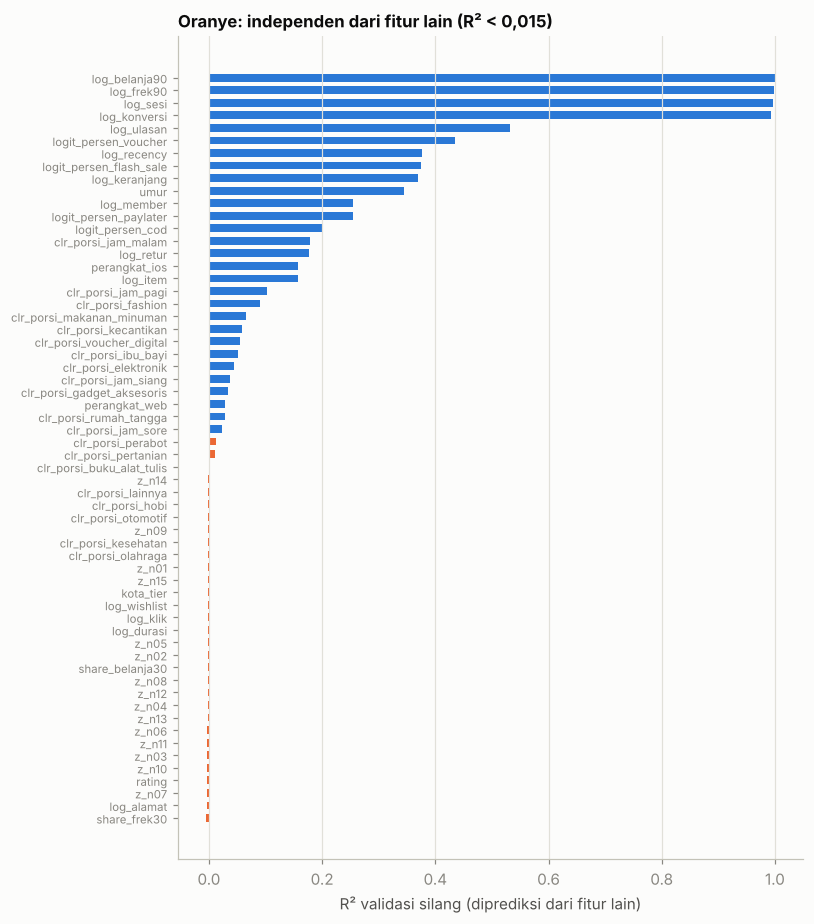

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 8.5))
p = pred.sort_values(); colors = [ORANGE if v < 0.015 else BLUE for v in p.values]
ax.barh(p.index, p.values, color=colors, height=0.62)
ax.set_xlabel('R² validasi silang (diprediksi dari fitur lain)'); ax.tick_params(axis='y', labelsize=7.5); ax.grid(axis='y', visible=False)
ax.set_title('Oranye: independen dari fitur lain (R² < 0,015)'); plt.tight_layout(); plt.show()

**Hasil**

- **Noise** ($R^2\approx 0$, korelasi Spearman terhadap fitur lain ≤ 0,010): `rating_beri_rata2`, `durasi_sesi_menit`, `kota_tier`, `jumlah_alamat`, `wishlist`, `klik_iklan_30h`, seluruh `n01–n15`, serta rasio 30 hari terhadap 90 hari.
- **Redundan** ($R^2\approx 1$): `belanja_90h` (0,999), `frekuensi_90h` (0,998; terprediksi dari `belanja_90h`), dan `rasio_konversi` (0,993; fungsi dari frekuensi dan sesi). Karena frekuensi dan belanja terkait identitas, `belanja_90h`, `belanja_30h`, `frekuensi_30h`, dan `rasio_konversi` dibuang.
- **Delapan kategori noise** (olahraga, hobi, otomotif, kesehatan, buku, lainnya, perabot, pertanian; $R^2\le 0{,}013$) digabung jadi satu bagian "sisa". Delapan kategori lain ($R^2$ 0,03–0,09) dipertahankan.

## 5. Model dasar, eta², dan ablasi fitur

Model dasar: K-Means dengan $k=6$ pada 26 fitur terpilih yang sudah distandarisasi ($z$-score). Selanjutnya dua bukti tambahan seleksi fitur:

- **Bukti 2, eta²**: seberapa besar variasi sebuah fitur dijelaskan oleh label cluster, $\eta^2=SS_{\text{antar}}/SS_{\text{total}}$.
- **Bukti 3, ablasi**: membuang atau menambah kelompok fitur lalu membandingkan partisi dengan model dasar (ARI, 1 berarti sama) dan silhouette.

In [8]:
# ---------- 1. model dasar ----------
sc = StandardScaler().fit(M.loc[akt, cols]); X = sc.transform(M.loc[akt, cols])
base = km(X, n_init=30); lab0 = base.labels_
print("ukuran:", np.bincount(lab0), "silhouette:", round(sil(X, lab0), 4), flush=True)

ukuran: [18773 27774 15845 27600  9984 11577] silhouette: 0.0833


In [9]:
# ---------- 2. eta^2 semua kandidat vs cluster dasar (bukti seleksi) ----------
def eta2(x, l):
    m = x.mean(); ss = ((x - m) ** 2).sum()
    return sum(((x[l == c].mean() - m) ** 2) * (l == c).sum() for c in np.unique(l)) / ss
kandidat = {}
for c in M.columns: kandidat[c] = ('terpilih' if c in cols else 'perangkat', M.loc[akt, c].to_numpy())
extra = ['log_belanja90','log_belanja30','log_frek30','log_konversi','rating','kota_tier','log_alamat','log_durasi','log_wishlist','log_klik'] + ['z_' + c for c in NOISE] + ['clr_' + c for c in KATEGORI if c in ['porsi_' + x[6:] for x in KAT_NOISE] or True]
for c in extra:
    if c in Fall.columns:
        grp = 'redundan' if c in ('log_belanja90','log_belanja30','log_frek30','log_konversi') else ('noise_kategori' if c.startswith('clr_porsi_') and ('porsi_' + c[10:]) in KAT_NOISE else ('noise' if c not in cols else 'terpilih'))
        if c.startswith('clr_porsi_jam') or (c.startswith('clr_porsi_') and ('porsi_' + c[10:]) in KAT_INFORMATIF): continue
        kandidat['F:' + c] = (grp, Fall.loc[akt, c].to_numpy())
eta = pd.DataFrame([(k, v[0], eta2(v[1].astype(float), lab0)) for k, v in kandidat.items()], columns=['fitur', 'status', 'eta2_vs_cluster']).sort_values('eta2_vs_cluster', ascending=False)
eta.round(4).to_csv(OUT + 'tabel_eta2_fitur.csv', index=False)
print(eta.groupby('status').eta2_vs_cluster.agg(['count', 'mean', 'max']).round(4), flush=True)

                count    mean     max
status                               
noise              21  0.0000  0.0001
noise_kategori      8  0.0051  0.0229
perangkat           2  0.0715  0.1379
redundan            4  0.3461  0.4690
terpilih           26  0.2344  0.5104


,count,mean,max
status,,,
noise,21,0.0000,0.0001
noise_kategori,8,0.0051,0.0229
perangkat,2,0.0715,0.1379
redundan,4,0.3461,0.4690
terpilih,26,0.2344,0.5104


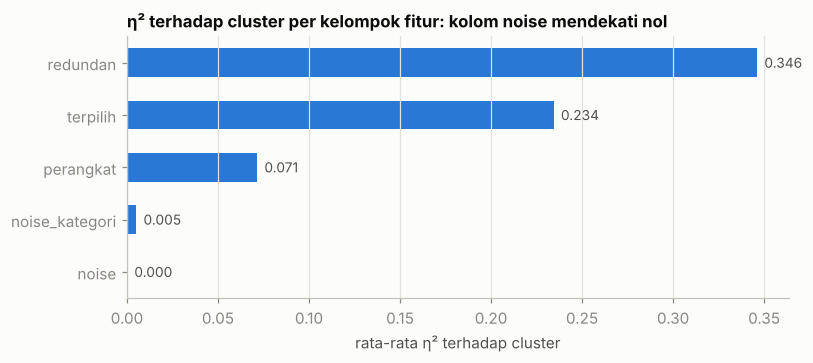

In [10]:
display(eta.groupby('status').eta2_vs_cluster.agg(['count', 'mean', 'max']).round(4))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
g = eta.groupby('status').eta2_vs_cluster.mean().sort_values()
ax.barh(g.index, g.values, color=BLUE, height=0.55); ax.grid(axis='y', visible=False)
for i, v in enumerate(g.values): ax.text(v + 0.004, i, f'{v:.3f}', va='center', color=INK2, fontsize=9)
ax.set_xlabel('rata-rata η² terhadap cluster'); ax.set_title('η² terhadap cluster per kelompok fitur: kolom noise mendekati nol')
plt.tight_layout(); plt.show()

Kelompok **redundan** memang berhubungan kuat dengan cluster, tetapi hanya karena mereka adalah turunan langsung dari frekuensi dan nilai keranjang (`belanja_90h` $=$ `frekuensi_90h` $\times$ `rata2_keranjang`). Mereka dibuang agar dimensi yang sama tidak terhitung dua kali, bukan karena tidak informatif. Yang menjadi bukti seleksi ialah kelompok **noise**: $\eta^2\approx 0$, artinya label cluster tidak menjelaskan variasi kolom-kolom itu sama sekali.

In [11]:
# ---------- 3. ablasi / penambahan kelompok fitur ----------
grp = {'rfm': ['log_recency','log_frek90','log_keranjang','log_item'], 'perilaku': ['log_retur','log_ulasan','log_sesi'],
       'persen': ['logit_' + c for c in PERSEN], 'jam': ['clr_' + c for c in JAM], 'kategori': [c for c in cols if c.startswith('clr_kat_')],
       'profil': ['log_member','umur']}
def run(cs, extra_df=None, label=''):
    A = M.loc[akt, [c for c in cs if c in M.columns]]
    if extra_df is not None: A = pd.concat([A, extra_df], axis=1)
    Z = StandardScaler().fit_transform(A); m = km(Z, n_init=8); return Z, m.labels_
rows = [('dasar (26 fitur)', len(cols), 1.0, sil(X, lab0))]
for g, cs in grp.items():
    Z, l = run([c for c in cols if c not in cs]); rows.append((f'- buang {g}', Z.shape[1], ari(lab0, l), sil(Z, l)))
Z, l = run(cols + ['perangkat_ios', 'perangkat_web']); rows.append(('+ perangkat', Z.shape[1], ari(lab0, l), sil(Z, l)))
noisecols = ['z_' + c for c in NOISE] + ['rating', 'kota_tier', 'log_alamat', 'log_durasi', 'log_wishlist', 'log_klik']
Z, l = run(cols, Fall.loc[akt, noisecols]); rows.append(('+ 21 kolom noise', Z.shape[1], ari(lab0, l), sil(Z, l)))
Z, l = run(cols, Fall.loc[akt, ['log_belanja90', 'log_belanja30', 'log_frek30', 'log_konversi']]); rows.append(('+ 4 kolom redundan', Z.shape[1], ari(lab0, l), sil(Z, l)))
Z, l = run([c for c in cols if not c.startswith('clr_kat_')], Fall.loc[akt, ['clr_' + c for c in KATEGORI]]); rows.append(('kategori: 16 CLR (tanpa amalgamasi)', Z.shape[1], ari(lab0, l), sil(Z, l)))
abl = pd.DataFrame(rows, columns=['skenario', 'n_fitur', 'ARI_vs_dasar', 'silhouette']).round(4)
abl.to_csv(OUT + 'tabel_ablasi_fitur.csv', index=False); print(abl.to_string(index=False), flush=True)

                           skenario  n_fitur  ARI_vs_dasar  silhouette
                   dasar (26 fitur)       26        1.0000      0.0833
                        - buang rfm       22        0.7814      0.0710
                   - buang perilaku       23        0.8451      0.0780
                     - buang persen       22        0.6228      0.0716
                        - buang jam       22        0.8867      0.0924
                   - buang kategori       17        0.8381      0.1164
                     - buang profil       24        0.7311      0.0725
                        + perangkat       28        0.7416      0.0785
                   + 21 kolom noise       47        0.9938      0.0432
                 + 4 kolom redundan       30        0.5298      0.0731
kategori: 16 CLR (tanpa amalgamasi)       33        0.9596      0.0631


**Membaca ablasi**

- Menambah 21 kolom noise hampir tidak mengubah partisi (ARI 0,994) tetapi menurunkan silhouette separuhnya (0,083 → 0,043): mereka hanya menambah derau.
- Menambah 4 kolom redundan mengubah partisi besar-besaran (ARI 0,53) karena frekuensi dan belanja terhitung berulang.
- Membuang tiap kelompok informatif mengubah partisi (ARI 0,62–0,89): tiap kelompok ikut membentuk segmen.
- Memasukkan `perangkat` (biner) menggeser partisi (ARI 0,74) tanpa memperbaiki silhouette, jadi ia dipakai sebagai validasi saja.

## 6. Jumlah cluster dan perbandingan metode

**Kriteria untuk $k$**

1. **BIC GMM** (kovarians penuh): $\text{BIC}=-2\ln \hat L + p\ln n$; makin kecil makin baik. `reg_covar=0.05` mencegah komponen runtuh pada fitur diskret.
2. **Stabilitas bootstrap**: rata-rata ARI antar run pada himpunan evaluasi tetap.
3. **Silhouette**, Calinski-Harabasz, dan Davies-Bouldin sebagai pembanding.

Tiga metode dibandingkan: **K-Means**, **GMM kovarians penuh**, dan **Ward agglomerative** (pada subsampel 12.000, lalu pusat cluster diperluas ke seluruh data dengan *nearest centroid* karena Ward tidak bisa menjalankan seluruh data). *(Sel BIC dan perbandingan memakan beberapa menit.)*

In [12]:
idx = np.random.default_rng(SEED).permutation(len(X)); tr, te = idx[:30000], idx[30000:60000]
rows = []
for k in range(2, 13):
    g = GaussianMixture(k, covariance_type='full', n_init=5, random_state=SEED, reg_covar=0.05, max_iter=400).fit(X[tr])
    rows.append((k, g.bic(X[tr]), g.score(X[te]), g.weights_.min())); print(rows[-1], flush=True)
bic_df = pd.DataFrame(rows, columns=['k', 'BIC', 'heldout_loglik', 'bobot_min']).round(4); bic_df.to_csv(OUT + 'tabel_bic_gmm.csv', index=False)

(2, 1912034.5528811978, -31.751115112321543, np.float64(0.4323550581267127))


(3, 1902575.8429859858, -31.531625700457553, np.float64(0.16772261391567297))


(4, 1897879.3006936887, -31.404495361880493, np.float64(0.16442593274347037))


(5, 1894065.5529637162, -31.286263247205007, np.float64(0.1529314000683917))


(6, 1892496.1621432751, -31.20418454301735, np.float64(0.09095026142044554))


(7, 1890807.8741668288, -31.13003217971656, np.float64(0.06325327465572322))


(8, 1890425.3397491223, -31.067829897549174, np.float64(0.05733581122372035))


(9, 1890531.5884473552, -31.025827664817175, np.float64(0.035234235579241706))


(10, 1892711.3435944116, -31.003302007590513, np.float64(0.03606311482420272))


(11, 1891355.5756457222, -30.931892256481863, np.float64(0.040390299166536206))


(12, 1892949.510718891, -30.90422018717432, np.float64(0.03327389021685119))


In [13]:
X = StandardScaler().fit_transform(M.loc[akt, cols]); n = len(X)
rng_cmp = np.random.default_rng(SEED)
sil_idx = rng_cmp.choice(n, 10000, replace=False)
eval_idx = rng_cmp.choice(n, 20000, replace=False)           # himpunan evaluasi tetap untuk stabilitas
B = 5                                                    # jumlah bootstrap
boots = [rng_cmp.choice(n, 20000, replace=True) for _ in range(B)]
sub_w = rng_cmp.choice(n, 12000, replace=False)              # subsampel untuk Ward

def make(method, k, seed):
    if method == 'kmeans': return KMeans(k, n_init=10, random_state=seed)
    if method == 'gmm':    return GaussianMixture(k, covariance_type='full', n_init=3, reg_covar=0.05, max_iter=300, random_state=seed)
def fit_predict(method, k, Xfit, Xpred, seed):
    if method == 'ward':
        lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xfit)
        return NearestCentroid().fit(Xfit, lab).predict(Xpred)
    m = make(method, k, seed).fit(Xfit); return m.predict(Xpred)

rows = []
for method in ['kmeans', 'gmm', 'ward']:
    for k in range(3, 10):
        t = time.time()
        if method == 'ward':
            lab_all = fit_predict('ward', k, X[sub_w], X, SEED)
        else:
            lab_all = fit_predict(method, k, X[:], X, SEED) if method == 'kmeans' else fit_predict('gmm', k, X[rng_cmp.choice(n, 40000, replace=False)], X, SEED)
        r = dict(metode=method, k=k,
                 silhouette=silhouette_score(X[sil_idx], lab_all[sil_idx]),
                 CH=calinski_harabasz_score(X, lab_all), DB=davies_bouldin_score(X, lab_all),
                 ukuran_min=np.bincount(lab_all, minlength=k).min() / n)
        labs = [fit_predict(method, k, X[b] if method != 'ward' else X[b[:12000]], X[eval_idx], 100 + i) for i, b in enumerate(boots)]
        pair = [ari(a, b) for a, b in itertools.combinations(labs, 2)]
        r['ARI_stab_mean'] = float(np.mean(pair)); r['ARI_stab_min'] = float(np.min(pair))
        rows.append(r)
        print({a: (round(b, 4) if isinstance(b, float) else b) for a, b in r.items()}, f"{time.time()-t:.0f}s", flush=True)
        pd.DataFrame(rows).to_csv(OUT + 'tabel_perbandingan_metode.csv', index=False)
cmp_df = pd.DataFrame(rows)

{'metode': 'kmeans', 'k': 3, 'silhouette': 0.0998, 'CH': 10467.5681, 'DB': 2.5474, 'ukuran_min': np.float64(0.1831), 'ARI_stab_mean': 0.99, 'ARI_stab_min': 0.9885} 2s


{'metode': 'kmeans', 'k': 4, 'silhouette': 0.0905, 'CH': 8723.2, 'DB': 2.6982, 'ukuran_min': np.float64(0.1466), 'ARI_stab_mean': 0.9848, 'ARI_stab_min': 0.9828} 3s


{'metode': 'kmeans', 'k': 5, 'silhouette': 0.0809, 'CH': 7632.4404, 'DB': 3.0442, 'ukuran_min': np.float64(0.1435), 'ARI_stab_mean': 0.9737, 'ARI_stab_min': 0.9675} 3s


{'metode': 'kmeans', 'k': 6, 'silhouette': 0.0843, 'CH': 6829.9297, 'DB': 2.8007, 'ukuran_min': np.float64(0.0895), 'ARI_stab_mean': 0.9783, 'ARI_stab_min': 0.9756} 4s


{'metode': 'kmeans', 'k': 7, 'silhouette': 0.0779, 'CH': 6110.7262, 'DB': 3.0219, 'ukuran_min': np.float64(0.084), 'ARI_stab_mean': 0.9597, 'ARI_stab_min': 0.9519} 4s


{'metode': 'kmeans', 'k': 8, 'silhouette': 0.0731, 'CH': 5528.965, 'DB': 3.0942, 'ukuran_min': np.float64(0.0696), 'ARI_stab_mean': 0.8851, 'ARI_stab_min': 0.7833} 5s


... (11 outputs left out)

{'metode': 'ward', 'k': 6, 'silhouette': 0.0845, 'CH': 6786.8044, 'DB': 2.7595, 'ukuran_min': np.float64(0.0801), 'ARI_stab_mean': 0.8328, 'ARI_stab_min': 0.7428} 32s


{'metode': 'ward', 'k': 7, 'silhouette': 0.0812, 'CH': 5973.3862, 'DB': 2.7891, 'ukuran_min': np.float64(0.0589), 'ARI_stab_mean': 0.7806, 'ARI_stab_min': 0.652} 33s


{'metode': 'ward', 'k': 8, 'silhouette': 0.0799, 'CH': 5384.0886, 'DB': 2.7705, 'ukuran_min': np.float64(0.0502), 'ARI_stab_mean': 0.7478, 'ARI_stab_min': 0.684} 32s


{'metode': 'ward', 'k': 9, 'silhouette': 0.0749, 'CH': 4983.7312, 'DB': 2.8496, 'ukuran_min': np.float64(0.0465), 'ARI_stab_mean': 0.716, 'ARI_stab_min': 0.646} 33s


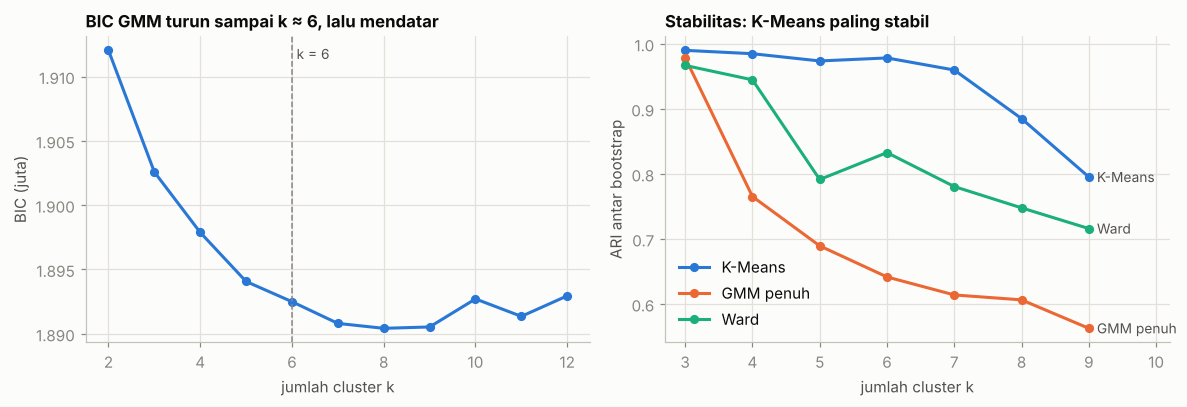

metode,gmm,kmeans,ward
Stabilitas (ARI),,,
3,0.979,0.990,0.967
4,0.765,0.985,0.945
5,0.689,0.974,0.791
6,0.642,0.978,0.833
7,0.614,0.960,0.781
8,0.606,0.885,0.748
9,0.563,0.795,0.716


metode,gmm,kmeans,ward
Silhouette,,,
3,0.099,0.100,0.100
4,0.084,0.091,0.090
5,0.069,0.081,0.084
6,0.063,0.084,0.084
7,0.062,0.078,0.081
8,0.068,0.073,0.080
9,0.058,0.071,0.075


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(bic_df.k, bic_df.BIC / 1e6, color=BLUE, lw=2, marker='o', ms=5)
ax.axvline(6, color=MUTED, lw=1, ls='--'); ax.text(6.1, 0.97, 'k = 6', transform=ax.get_xaxis_transform(), color=INK2, va='top', fontsize=9)
ax.set_xlabel('jumlah cluster k'); ax.set_ylabel('BIC (juta)'); ax.set_title('BIC GMM turun sampai k ≈ 6, lalu mendatar')
ax = axes[1]
ordr = [('kmeans', 'K-Means', BLUE), ('gmm', 'GMM penuh', ORANGE), ('ward', 'Ward', AQUA)]
for m, nm, col in ordr:
    s = cmp_df[cmp_df.metode == m]; ax.plot(s.k, s.ARI_stab_mean, color=col, lw=2, marker='o', ms=5, label=nm)
    ax.text(s.k.iloc[-1] + 0.12, s.ARI_stab_mean.iloc[-1], nm, color=INK2, va='center', fontsize=9)
ax.set_xlim(2.7, 10.2); ax.set_xlabel('jumlah cluster k'); ax.set_ylabel('ARI antar bootstrap'); ax.set_title('Stabilitas: K-Means paling stabil'); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()
display(cmp_df.pivot(index='k', columns='metode', values='ARI_stab_mean').round(3).rename_axis('Stabilitas (ARI)'))
display(cmp_df.pivot(index='k', columns='metode', values='silhouette').round(3).rename_axis('Silhouette'))

**Keputusan $k=6$ dan metode**

- BIC turun jelas sampai $k=6$ lalu mendatar; BIC saja **tidak** menentukan satu $k$ (nilai terkecil di $k=8$, tetapi selisih $k=6$ ke $8$ hanya sekitar 0,1%).
- K-Means tetap stabil (ARI ≥ 0,96) sampai $k=7$ lalu jatuh pada $k=8$ dan 9. Silhouette ($\approx$ 0,07–0,10) dan Calinski-Harabasz turun pelan tanpa siku; silhouette tertinggi di $k=3$ tetapi tiga segmen terlalu kasar untuk tindakan pemasaran.
- Dipilih $k=6$: $k$ terkecil pada dataran BIC dengan partisi yang stabil.
- GMM kovarians penuh memberi BIC terbaik tetapi **tidak stabil** untuk $k\ge4$ (optimum lokal), sehingga tidak dipakai sebagai model final. K-Means paling stabil dan sejalan dengan Ward, jadi K-Means dipakai.
- HDBSCAN tidak dijalankan: pada sekitar 26 dimensi dengan segmen yang tumpang tindih, metode berbasis kerapatan kurang cocok (asumsi, belum diuji).

## 7. Sensitivitas, kesepakatan antar metode, stabilitas, dan anomali tambahan

- **Sensitivitas**: apakah $\delta$ pada CLR dan pilihan $k$ mengubah partisi besar-besaran?
- **Kesepakatan antar metode** pada $k=6$ (ARI K-Means, GMM, Ward).
- **Stabilitas pipeline final**: 10 bootstrap 30.000 baris (scaler dan K-Means dilatih ulang tiap kali), lalu tiap model memberi label ke seluruh pelanggan aktif; dilaporkan ARI antar run.
- **Anomali**: Isolation Forest pada fitur aplikasi harus identik dengan aturan; Isolation Forest pada seluruh fitur terpilih dipakai untuk memeriksa ada tidaknya kelompok anomali kedua.

In [15]:
# ---------- 4. sensitivitas delta CLR dan k ----------
sens = []
for d in (5e-6, 5e-4):
    Md, _ = build_model_matrix(df, delta=d); Zd = StandardScaler().fit_transform(Md.loc[akt, cols]); sens.append((f'delta CLR = {d:g}', ari(lab0, km(Zd, n_init=8).labels_)))
for k2 in (5, 7):
    sens.append((f'k = {k2} vs k = 6', ari(lab0, km(X, k2, n_init=8).labels_)))
print(sens, flush=True)

[('delta CLR = 5e-06', 0.9822792293709744), ('delta CLR = 0.0005', 0.9830054720222399), ('k = 5 vs k = 6', 0.8830116752221158), ('k = 7 vs k = 6', 0.8493175955235468)]


In [16]:
# ---------- 5. kesepakatan antar metode (k=6) ----------
sub = rng.choice(len(X), 40000, replace=False); subw = rng.choice(len(X), 12000, replace=False)
l_gmm = GaussianMixture(K, covariance_type='full', n_init=3, reg_covar=0.05, max_iter=300, random_state=SEED).fit(X[sub]).predict(X)
l_ward = NearestCentroid().fit(X[subw], AgglomerativeClustering(K, linkage='ward').fit_predict(X[subw])).predict(X)
agree = {'KMeans~GMM': ari(lab0, l_gmm), 'KMeans~Ward': ari(lab0, l_ward), 'GMM~Ward': ari(l_gmm, l_ward)}
print("kesepakatan:", {a: round(b, 3) for a, b in agree.items()}, flush=True)

kesepakatan: {'KMeans~GMM': 0.716, 'KMeans~Ward': 0.879, 'GMM~Ward': 0.689}


In [17]:
# ---------- 6. stabilitas bootstrap (pipeline final: scaler + K-Means) ----------
labs = []
for i in range(10):
    b = rng.choice(len(M.loc[akt]), 30000, replace=True); Xb = M.loc[akt, cols].to_numpy()[b]
    scb = StandardScaler().fit(Xb); mb = km(scb.transform(Xb), n_init=10, seed=200 + i)
    labs.append(mb.predict(scb.transform(M.loc[akt, cols].to_numpy())))
pair = [ari(a, b) for a, b in itertools.combinations(labs, 2)]; vs_final = [ari(a, lab0) for a in labs]
stab = dict(ARI_antar_bootstrap_mean=float(np.mean(pair)), ARI_antar_bootstrap_sd=float(np.std(pair)), ARI_antar_bootstrap_min=float(np.min(pair)), ARI_vs_final_mean=float(np.mean(vs_final)))
print("stabilitas:", {a: round(b, 4) for a, b in stab.items()}, flush=True)

stabilitas: {'ARI_antar_bootstrap_mean': 0.9822, 'ARI_antar_bootstrap_sd': 0.0018, 'ARI_antar_bootstrap_min': 0.9772, 'ARI_vs_final_mean': 0.9874}


In [18]:
# ---------- 7. anomali ----------
Fapp = np.column_stack([np.log(df.sesi_per_minggu), np.log(df.durasi_sesi_menit), np.log1p(df.klik_iklan_30h), np.log1p(df.wishlist)])
iso = IsolationForest(n_estimators=200, contamination=bot.mean(), random_state=SEED).fit(Fapp); pi = iso.predict(Fapp) == -1
tp = (pi & bot).sum(); anom = dict(IF_flag=int(pi.sum()), aturan_flag=int(bot.sum()), overlap=int(tp), presisi_IF=float(tp / pi.sum()), recall_IF=float(tp / bot.sum()))
Xs = sc.transform(M.loc[akt, cols]); dist = np.sqrt(((Xs - base.cluster_centers_[lab0]) ** 2).sum(1))
anom['jarak_ke_pusat_q'] = {q: float(np.quantile(dist, q)) for q in (0.5, 0.9, 0.99, 0.999)}
iso2 = IsolationForest(n_estimators=200, random_state=SEED).fit(Xs); s2 = -iso2.score_samples(Xs)
anom['IF_semua_fitur_skor_q'] = {q: float(np.quantile(s2, q)) for q in (0.5, 0.9, 0.99, 0.999)}
print("anomali:", anom, flush=True)

anomali: {'IF_flag': 1800, 'aturan_flag': 1800, 'overlap': 1800, 'presisi_IF': 1.0, 'recall_IF': 1.0, 'jarak_ke_pusat_q': {0.5: 4.275616718232768, 0.9: 5.529376721407449, 0.99: 6.845077905921094, 0.999: 8.557898580370034}, 'IF_semua_fitur_skor_q': {0.5: 0.43721330514301615, 0.9: 0.4747268073108577, 0.99: 0.5106505461785841, 0.999: 0.5378695246308651}}


Isolation Forest pada empat fitur aplikasi menandai **tepat himpunan yang sama** dengan aturan (presisi 1,0 dan recall 1,0), dan skor Isolation Forest atas seluruh fitur terpilih tidak menunjukkan celah (kuantil 0,99 dan 0,999 berdekatan), jadi tidak ada kelompok anomali kedua. Karena itu tidak ada tambahan label `-1` di luar 1.800 pelanggan tersebut.

## 8. Label akhir dan `cluster.csv`

- Pelanggan **aktif** mendapat label dari K-Means final ($k=6$, `n_init=30`).
- Pelanggan **tanpa transaksi** diberi segmen terdekat dengan jarak ke pusat yang dihitung **hanya pada dimensi yang teramati** (tanpa `log_keranjang` dan `log_ulasan`). Ini setara dengan marginalisasi dimensi yang tidak terdefinisi.
- **Anomali** diberi `-1`.

In [19]:
# ---------- 8. label akhir ----------
full = np.full(len(df), -2, int)
full[akt] = lab0
obs = [c for c in cols if c not in KOLOM_STRUKTURAL]
ii = [cols.index(c) for c in obs]
tgt = (nol & ~bot)
Xn = (M.loc[tgt, obs].to_numpy() - sc.mean_[ii]) / sc.scale_[ii]
C = base.cluster_centers_[:, ii]
full[tgt] = ((Xn[:, None, :] - C[None]) ** 2).sum(2).argmin(1)     # marginalisasi dimensi struktural: jarak hanya pada dimensi teramati
full[bot] = -1
assert (full != -2).all()
cl = pd.DataFrame({'id_pelanggan': df.id_pelanggan, 'cluster': full})
cl.to_csv(OUT + 'cluster.csv', index=False); cl.to_csv('cluster.csv', index=False)  # salinan di folder kerja (ketentuan soal: cluster.csv di akar repo)
print("tersimpan; sebaran:", cl.cluster.value_counts().sort_index().to_dict(), flush=True)

tersimpan; sebaran: {-1: 1800, 0: 23891, 1: 28000, 2: 16015, 3: 27615, 4: 10993, 5: 11686}


In [20]:
chk = pd.read_csv('cluster.csv')
assert list(chk.columns) == ['id_pelanggan', 'cluster'] and len(chk) == len(df) and chk.id_pelanggan.is_unique
assert set(chk.id_pelanggan) == set(df.id_pelanggan) and chk.cluster.dtype.kind == 'i' and chk.cluster.notna().all()
print('cluster.csv valid:', chk.shape, '| sebaran:', chk.cluster.value_counts().sort_index().to_dict())
tz = chk.merge(df[['id_pelanggan', 'frekuensi_90h']], on='id_pelanggan').query('frekuensi_90h == 0 and cluster >= 0')
print('Sebaran pelanggan tanpa transaksi non-bot per segmen (%):'); print((tz.cluster.value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

cluster.csv valid: (120000, 2) | sebaran: {-1: 1800, 0: 23891, 1: 28000, 2: 16015, 3: 27615, 4: 10993, 5: 11686}
Sebaran pelanggan tanpa transaksi non-bot per segmen (%):
{0: 77.0, 1: 3.4, 2: 2.6, 3: 0.2, 4: 15.2, 5: 1.6}


## 9. Profil segmen dan aksi pemasaran

Rata-rata fitur asli (`profil_segmen.csv`) dan $z$-score rata-rata per cluster pada fitur terpilih (`profil_segmen_zscore.csv`). Nilai $z$ positif berarti di atas rata-rata seluruh pelanggan aktif.

In [21]:
# ---------- 9. profil ----------
prof_cols = ['recency_hari','frekuensi_90h','belanja_90h','rata2_keranjang','item_per_pesanan','persen_voucher','persen_flash_sale','persen_paylater','persen_cod',
             'porsi_jam_pagi','porsi_jam_siang','porsi_jam_sore','porsi_jam_malam','retur_90h','ulasan_90h','sesi_per_minggu','lama_member_bulan','umur'] + KAT_INFORMATIF
P = df.assign(cluster=full).query('cluster >= 0').groupby('cluster')[prof_cols].mean().round(3); P.insert(0, 'n', cl.cluster.value_counts().sort_index().loc[lambda s: s.index >= 0])
P['pct_ios'] = df.assign(cluster=full, ios=(df.perangkat == 'ios')).query('cluster >= 0').groupby('cluster').ios.mean().round(3)
P['pct_web'] = df.assign(cluster=full, web=(df.perangkat == 'web')).query('cluster >= 0').groupby('cluster').web.mean().round(3)
P['pct_tanpa_transaksi'] = df.assign(cluster=full, z=nol).query('cluster >= 0').groupby('cluster').z.mean().round(3)
P.to_csv(OUT + 'profil_segmen.csv')
Z = pd.DataFrame(X, columns=cols).groupby(lab0).mean().round(2); Z.to_csv(OUT + 'profil_segmen_zscore.csv')
json.dump(dict(stabilitas=stab, kesepakatan=agree, sensitivitas=sens, anomali=anom, ukuran=cl.cluster.value_counts().sort_index().to_dict(), silhouette=float(sil(X, lab0))),
          open(OUT + 'ringkasan_final.json', 'w'), indent=1, default=float)
print(P.T.to_string()); print(Z.T.to_string())

cluster                          0            1            2            3           4            5
n                        23891.000    28000.000    16015.000    27615.000   10993.000    11686.000
recency_hari                78.099       11.906        9.829        8.070      16.467       12.190
frekuensi_90h                2.252        9.240        9.051       19.568       3.829        9.176
belanja_90h             503017.132  1122003.843  6672679.900  6011711.928  733290.958  1928291.349
rata2_keranjang         224993.688   121806.474   732597.577   279782.986  189835.837   211197.046
item_per_pesanan             2.537        2.406        2.216        5.090       2.478        2.419
persen_voucher               0.445        0.812        0.191        0.402       0.531        0.583
persen_flash_sale            0.348        0.676        0.184        0.267       0.403        0.554
persen_paylater              0.238        0.223        0.131        0.169       0.230        0.763
persen_cod

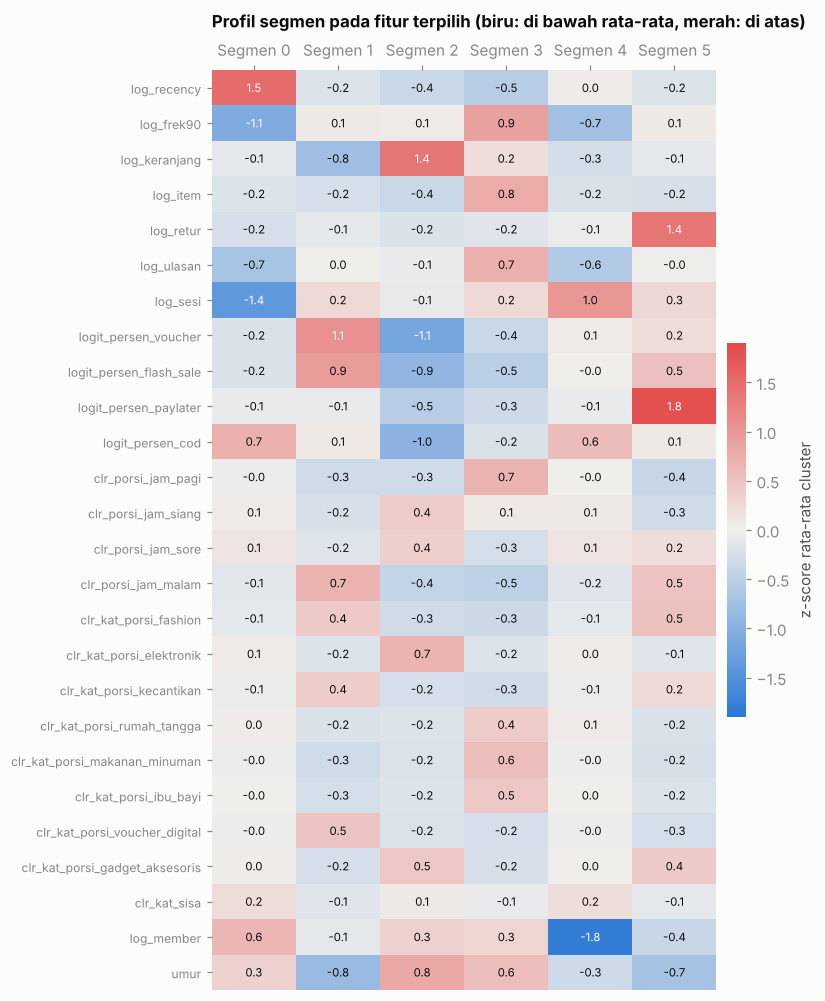

In [22]:
Zt = Z.T                                              # baris: fitur, kolom: cluster
cmap = LinearSegmentedColormap.from_list('div', [BLUE, '#f0efec', RED])   # dua kutub + abu netral
fig, ax = plt.subplots(figsize=(7.6, 9.2))
lim = float(np.ceil(np.abs(Zt.values).max() * 10) / 10)
im = ax.imshow(Zt.values, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto')
ax.set_xticks(range(Zt.shape[1])); ax.set_xticklabels([f'Segmen {c}' for c in Zt.columns]); ax.xaxis.tick_top()
ax.set_yticks(range(Zt.shape[0])); ax.set_yticklabels(Zt.index, fontsize=8); ax.grid(False)
for s in ax.spines.values(): s.set_visible(False)
for i in range(Zt.shape[0]):
    for j in range(Zt.shape[1]):
        v = Zt.values[i, j]; ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=7.5, color='#ffffff' if abs(v) > 0.55 * lim else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.set_label('z-score rata-rata cluster', color=INK2); cb.outline.set_visible(False)
ax.set_title('Profil segmen pada fitur terpilih (biru: di bawah rata-rata, merah: di atas)', pad=28, loc='left')
plt.tight_layout(); plt.show()

In [23]:
ukuran_dikenal = {0: 23891, 1: 28000, 2: 16015, 3: 27615, 4: 10993, 5: 11686}
ukuran_kini = pd.Series(full[full >= 0]).value_counts().sort_index().to_dict()
if ukuran_kini != ukuran_dikenal:
    print('PERINGATAN: ukuran cluster berbeda dari run acuan (versi library lain?). Nomor cluster di tabel nama di bawah mungkin tertukar;')
    print('cocokkan nama dengan profil di atas (mis. segmen dengan recency tertinggi = Pelanggan Tidur).')
nama = {
 0: ('Pelanggan Tidur',            'recency 78 hari; frekuensi 2,3; sesi 2,4/minggu; member 33 bulan; 21% tanpa transaksi', 'Kampanye win-back: voucher berbatas waktu dan pengingat wishlist'),
 1: ('Pemburu Promo Malam',        '81% pesanan pakai voucher dan 68% flash sale; 43% belanja malam; umur 26; keranjang Rp122 rb', 'Flash sale malam dengan notifikasi sebelum mulai; bundel fashion-kecantikan'),
 2: ('Premium Elektronik',         'keranjang Rp733 rb; belanja Rp6,7 jt per 90 hari; 66% iOS; elektronik dan gadget; voucher 19%', 'Akses awal, pengiriman prioritas, cicilan 0%, bukan diskon'),
 3: ('Langganan Kebutuhan Rumah',  'frekuensi 19,6; 5,1 barang per pesanan; 40% belanja pagi; makanan, rumah tangga, ibu-bayi', 'Langganan isi ulang otomatis, paket hemat grosir, gratis ongkir minimum belanja'),
 4: ('Pendatang Baru',             'member 4,4 bulan; sesi 12,6/minggu; frekuensi 3,8; COD 43%', 'Onboarding: voucher ongkir pesanan ke-2 dan ke-3, dorong pembayaran non-COD'),
 5: ('Paylater dengan Retur Tinggi','76% pesanan paylater; retur 2,9 (segmen lain 0,6-0,8); flash sale 55%; umur 27', 'Panduan ukuran/kualitas untuk menekan retur; limit paylater dinamis dan pengingat jatuh tempo'),
}
tbl = pd.DataFrame([(c, ukuran_kini.get(c), *nama[c]) for c in sorted(nama)], columns=['segmen', 'n', 'nama', 'ciri utama', 'aksi pemasaran'])
tbl.loc[len(tbl)] = ['-1', int(bot.sum()), 'Anomali (bot)', 'sesi ±241/minggu, durasi 0,6 menit, klik iklan dan wishlist sangat tinggi', 'Tandai ke tim anti-fraud; keluarkan dari metrik pemasaran']
tbl.to_csv(OUT + 'tabel_nama_segmen.csv', index=False)
pd.set_option('display.max_colwidth', 120); display(tbl)

,segmen,n,nama,ciri utama,aksi pemasaran
0,0,23891,Pelanggan Tidur,"recency 78 hari; frekuensi 2,3; sesi 2,4/minggu; member 33 bulan; 21% tanpa transaksi",Kampanye win-back: voucher berbatas waktu dan pengingat wishlist
1,1,28000,Pemburu Promo Malam,81% pesanan pakai voucher dan 68% flash sale; 43% belanja malam; umur 26; keranjang Rp122 rb,Flash sale malam dengan notifikasi sebelum mulai; bundel fashion-kecantikan
2,2,16015,Premium Elektronik,"keranjang Rp733 rb; belanja Rp6,7 jt per 90 hari; 66% iOS; elektronik dan gadget; voucher 19%","Akses awal, pengiriman prioritas, cicilan 0%, bukan diskon"
3,3,27615,Langganan Kebutuhan Rumah,"frekuensi 19,6; 5,1 barang per pesanan; 40% belanja pagi; makanan, rumah tangga, ibu-bayi","Langganan isi ulang otomatis, paket hemat grosir, gratis ongkir minimum belanja"
4,4,10993,Pendatang Baru,"member 4,4 bulan; sesi 12,6/minggu; frekuensi 3,8; COD 43%","Onboarding: voucher ongkir pesanan ke-2 dan ke-3, dorong pembayaran non-COD"
5,5,11686,Paylater dengan Retur Tinggi,"76% pesanan paylater; retur 2,9 (segmen lain 0,6-0,8); flash sale 55%; umur 27",Panduan ukuran/kualitas untuk menekan retur; limit paylater dinamis dan pengingat jatuh tempo
6,-1,1800,Anomali (bot),"sesi ±241/minggu, durasi 0,6 menit, klik iklan dan wishlist sangat tinggi",Tandai ke tim anti-fraud; keluarkan dari metrik pemasaran


**Validasi eksternal.** `perangkat` tidak dipakai membentuk cluster, tetapi proporsi iOS berbeda tajam antar segmen (sekitar 66% pada Premium Elektronik versus 15–24% pada segmen lain; lihat kolom `pct_ios` pada tabel profil di atas). Itu menunjukkan segmen bermakna pada dimensi di luar fitur yang dipakai.

## 10. Ringkasan dan keterbatasan

In [24]:
ring = json.load(open(OUT + 'ringkasan_final.json'))
print('Segmen            : 6 (K-Means), anomali -1 :', int(bot.sum()))
print('Silhouette (aktif):', round(ring['silhouette'], 4))
print('Stabilitas ARI    :', {k: round(v, 4) for k, v in ring['stabilitas'].items()})
print('Kesepakatan metode:', {k: round(v, 3) for k, v in ring['kesepakatan'].items()})
print('Sensitivitas      :', [(a_, round(b_, 3)) for a_, b_ in ring['sensitivitas']])

Segmen            : 6 (K-Means), anomali -1 : 1800
Silhouette (aktif): 0.0833
Stabilitas ARI    : {'ARI_antar_bootstrap_mean': 0.9822, 'ARI_antar_bootstrap_sd': 0.0018, 'ARI_antar_bootstrap_min': 0.9772, 'ARI_vs_final_mean': 0.9874}
Kesepakatan metode: {'KMeans~GMM': 0.716, 'KMeans~Ward': 0.879, 'GMM~Ward': 0.689}
Sensitivitas      : [('delta CLR = 5e-06', 0.982), ('delta CLR = 0.0005', 0.983), ('k = 5 vs k = 6', 0.883), ('k = 7 vs k = 6', 0.849)]


**Keterbatasan**

- Silhouette sekitar 0,08 menunjukkan segmen **saling tumpang tindih**: stabilitas tinggi (ARI 0,98) berarti partisinya konsisten, bukan berarti sama dengan segmen referensi dosen.
- ARI terhadap referensi belum bisa dihitung; $k=6$ dipilih lewat kriteria internal dan bisa meleset bila referensi memakai $k$ lain.
- Segmen untuk pelanggan tanpa transaksi (5,6% data) ditentukan dari dimensi yang teramati saja.
- GMM tidak stabil dan HDBSCAN tidak diuji, sehingga perbandingan lebih kuat untuk K-Means dan Ward.
- Penggunaan alat AI (Claude) untuk membantu menulis dan memeriksa kode ini perlu dicantumkan di `kontribusi.md`, beserta cara tim memverifikasinya.